# **4 - Machine Learning y Validación**

In [22]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

In [23]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV,
    KFold,
)
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)
# Usaremos estas distribuciones para samplear en el RandomSearchCV
from scipy.stats import randint, uniform, loguniform

In [24]:
# Cargamos los datasets
PROJECT_DIR = Path().resolve() if EN_COLAB else Path().resolve().parent
DATA_BASE_DIR = PROJECT_DIR / "datos" / "procesados"

df = pd.read_csv(DATA_BASE_DIR / "milan_airbnb_filtrado.csv")

In [25]:
TARGET = "log_daily_price"

X, y = df.drop(columns=TARGET), df[TARGET]

In [26]:
X.columns, len(X.columns)

(Index(['host_is_superhost', 'host_total_listings_count',
        'neighbourhood_cleansed', 'accommodates', 'bathrooms', 'bedrooms',
        'guests_included', 'minimum_nights', 'availability_365',
        'number_of_reviews', 'review_scores_rating', 'TV', 'WiFi',
        'Air_Condition', 'Breakfast', 'Elevator', 'Washer', 'Iron',
        'Host_greets_you', 'Paid_parking_on_premises',
        'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman',
        'Pets_allowed', 'Smoking_allowed', 'check_in_24_hour'],
       dtype='str'),
 26)

Separamos los features en sus respectivas categorias para poder usar un pipeline.


In [27]:
# 1. Variables numéricas
numeric_features = [
    "host_total_listings_count",
    "accommodates",
    "bathrooms",
    "bedrooms",
    "guests_included",
    "minimum_nights",
    "availability_365",
    "number_of_reviews",
    "review_scores_rating"
]

# 2. Variables categóricas nominales
categorical_features = ["neighbourhood_cleansed"]

# 3. Variables binarias
binary_features = [
    "host_is_superhost",
    "TV",
    "WiFi",
    "Air_Condition",
    "Breakfast",
    "Elevator",
    "Washer",
    "Iron",
    "Host_greets_you",
    "Paid_parking_on_premises",
    "Luggage_dropoff_allowed",
    "Long_term_stays_allowed",
    "Doorman",
    "Pets_allowed",
    "Smoking_allowed",
    "check_in_24_hour"
]

all_features = numeric_features + categorical_features + binary_features

X = X[all_features]

## 1. Dividimos en train y test

In [28]:
TEST_SIZE = 0.2
RANDOM_STATE = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    shuffle=True,
    random_state=RANDOM_STATE
)

print(f"Total de registros en la base: {df.shape[0]}")
print(f"Registros para ENTRENAR los modelos (X_train): {X_train.shape[0]}")
print(f"Registros para TESTEAR los modelos (X_test): {X_test.shape[0]}")
print(f"Cantidad de variables predictoras: {X_train.shape[1]}")


# print("\n============== MUESTRA ==============")
# print(f"Total de registros en la base: {df_muestra.shape[0]}")
# print(f"Registros para ENTRENAR los modelos (X_train): {X_train_muestra.shape[0]}")
# print(f"Registros para TESTEAR los modelos (X_test): {X_test_muestra.shape[0]}")
# print(f"Cantidad de variables predictoras: {X_train_muestra.shape[1]}")

Total de registros en la base: 9297
Registros para ENTRENAR los modelos (X_train): 7437
Registros para TESTEAR los modelos (X_test): 1860
Cantidad de variables predictoras: 26


## 2. Implementación de Algoritmos:

Para el entrenamiento y comparación de modelos se seleccionaron tres algoritmos: Random Forest, Gradient Boosting y k-Nearest Neighbors (k-NN).
La elección buscó representar distintos enfoques de aprendizaje supervisado vistos en clase

- **Random Forest Regressor**: como representante de los métodos basados en árboles de decisión y técnicas de bagging, ya que combina múltiples árboles para reducir la varianza y mejorar la capacidad de generalización.
- **Gradient Boosting**: como representante de los métodos de boosting, que construyen árboles de manera secuencial, buscando corregir los errores de las predicciones anteriores.
- **k-NN** como un enfoque alternativo, más simple y conceptualmente diferente de los anteriores, dado que realiza predicciones a partir de la proximidad entre observaciones, sin construir un conjunto de árboles.

En una primera etapa, entrenaremos los tres algoritmos seleccionados (Random Forest, Gradient Boosting y KNN) utilizando sus hiperparámetros por defecto, con el objetivo de establecer un piso que permita comparar sus desempeños antes de realizar cualquier optimización.

In [29]:
# 1. Random Forest Regressor
reg_rf = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 2. Gradient Boosting Regressor
reg_gb = GradientBoostingRegressor(
    random_state=RANDOM_STATE
)

# Preprocesador/Transofrmador para el entrenamiento del Random Forest y Gradient Boosting
preprocessor_trees = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

pipeline_gb = Pipeline([
    ("preprocessor", preprocessor_trees),
    ("regressor", reg_gb)
])

pipeline_rf = Pipeline([
    ("preprocessor", preprocessor_trees),
    ("regressor", reg_rf)
])

# 3. k-Nearest Neighbors Regressor
reg_knn = KNeighborsRegressor(
    n_jobs=-1
)

# KNN
preprocessor_knn = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    remainder="drop"
)

pipeline_knn = Pipeline([
    ("preprocessor", preprocessor_knn),
    ("regressor", reg_knn)
])

## **3. Evaluación de Métricas:**
Sobre los conjuntos de entrenamiento (train) y prueba (test), se calculemos las métricas MAE, MSE, RMSE y R² sobre ambos conjuntos. Esta comparación permitirá identificar posibles indicios de sobreajuste (overfitting), observando las diferencias entre el rendimiento en entrenamiento y en datos no vistos.

In [30]:
def entrenar_y_evaluar(modelo, X_train, y_train, X_test, y_test):
    # Entrenamos el modelo
    modelo.fit(X_train, y_train)

    # Generamos las predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Calculamos las métricas
    metricas = {
        "Train": {
            "MAE": mean_absolute_error(y_train, pred_train),
            "MSE": mean_squared_error(y_train, pred_train),
            "RMSE": np.sqrt(mean_squared_error(y_train, pred_train)),
            "R2": r2_score(y_train, pred_train)
        },
        "Test": {
            "MAE": mean_absolute_error(y_test, pred_test),
            "MSE": mean_squared_error(y_test, pred_test),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred_test)),
            "R2": r2_score(y_test, pred_test)
        }
    }

    return pd.DataFrame(metricas).T

In [31]:
modelos_default = {
    "RandomForest": pipeline_rf,
    "GradientBoosting": pipeline_gb,
    "KNN": pipeline_knn
}

resultados_default = {}

for nombre, modelo in modelos_default.items():
    resultados_default[nombre] = entrenar_y_evaluar(
        modelo,
        X_train,
        y_train,
        X_test,
        y_test
    )

    print(f"\n{'='*15} {nombre} {'='*15}")
    display(resultados_default[nombre].round(4))


=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Train,0.1120,0.0251,0.1584,0.9197
Test,0.2893,0.1661,0.4075,0.4511



=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Train,0.2823,0.1557,0.3945,0.5017
Test,0.2843,0.1618,0.4022,0.4652



=============== KNN ===============


,MAE,MSE,RMSE,R2
Train,0.2673,0.1405,0.3748,0.5502
Test,0.3262,0.2091,0.4573,0.3087


In [32]:
df_default = pd.concat(
    resultados_default,
    names=["Modelo", "Conjunto"]
)

display(df_default.round(4))

MAE     MSE    RMSE      R2
Modelo           Conjunto                                
RandomForest     Train     0.1120  0.0251  0.1584  0.9197
                 Test      0.2893  0.1661  0.4075  0.4511
GradientBoosting Train     0.2823  0.1557  0.3945  0.5017
                 Test      0.2843  0.1618  0.4022  0.4652
KNN              Train     0.2673  0.1405  0.3748  0.5502
                 Test      0.3262  0.2091  0.4573  0.3087

Conjunto,Modelo,R² Train,R² Test,Diferencia
0,RandomForest,0.9197,0.4511,0.4686
1,GradientBoosting,0.5017,0.4652,0.0365
2,KNN,0.5502,0.3087,0.2415


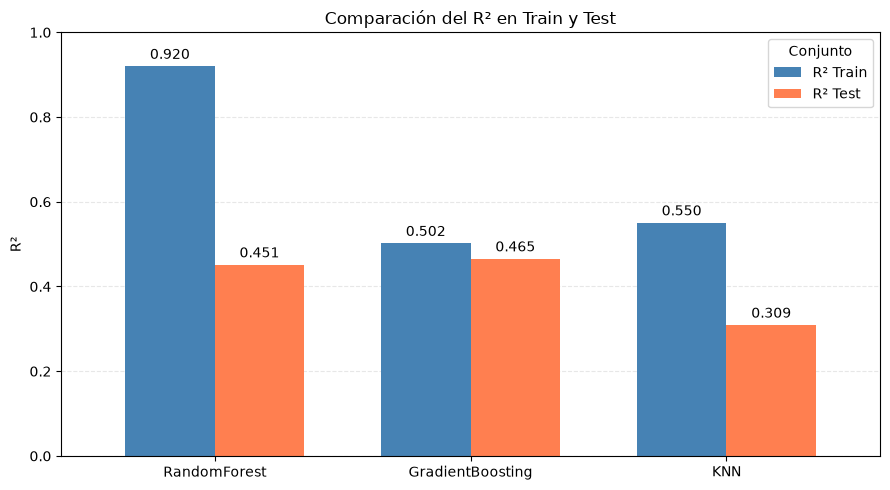

In [33]:
# Extraemos el R² de Train y Test para cada modelo
df_r2 = (
    df_default["R2"]
    .unstack("Conjunto")
    [["Train", "Test"]]
    .rename(columns={
        "Train": "R² Train",
        "Test": "R² Test"
    })
    .reset_index()
)

# Calculamos la diferencia entre Train y Test
df_r2["Diferencia"] = df_r2["R² Train"] - df_r2["R² Test"]

# Mostramos la tabla
display(df_r2.round(4))

# Gráfico
ax = df_r2.plot(
    x="Modelo",
    y=["R² Train", "R² Test"],
    kind="bar",
    figsize=(9, 5),
    rot=0,
    width=0.7,
    color=["steelblue", "coral"]
)

ax.set_title("Comparación del R² en Train y Test")
ax.set_xlabel("")
ax.set_ylabel("R²")
ax.set_ylim(0, 1)
ax.legend(title="Conjunto")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

# Mostrar valores sobre las barras
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()

### Análisis de sobreajuste

Al comparar el R² entre entrenamiento y prueba, podemos ver diferencias bastante claras en cómo generalizan los tres modelos.

**Random Forest** presentó un sobreajuste considerable, con un R² de 0.919 en entrenamiento que cae a 0.453 en test, dejando una brecha de 0.466. Esto indica que el modelo se ajusta muy bien a los datos de entrenamiento, pero pierde bastante rendimiento al enfrentarse a datos nuevos.

Por su parte, **KNN** también mostró indicios de sobreajuste, aunque menos marcados, con una diferencia de 0.241 entre entrenamiento (0.550) y test (0.309). Además, fue el modelo que obtuvo el peor rendimiento predictivo.

En cambio, **Gradient Boosting** mostró un comportamiento mucho más equilibrado, con un R² de 0.502 en entrenamiento y 0.462 en test, es decir, una diferencia de apenas 0.040. Esto sugiere que logra generalizar bastante bien lo aprendido, sin mostrar señales importantes de sobreajuste.

En resumen, **Gradient Boosting fue el modelo que mejores resultados obtuvo inicialmente**, tanto por su rendimiento en test como por la poca diferencia respecto del entrenamiento. De todas formas, su ventaja sobre Random Forest en test fue bastante pequeña (0.462 frente a 0.453).

En la siguiente etapa, vamos a aplicar validación cruzada y optimización de hiperparámetros para intentar mejorar las predicciones y controlar el sobreajuste, especialmente en Random Forest y KNN.

## 4. Optimización
Con el objetivo de mejorar el desempeño predictivo y reducir el sobreajuste observado en algunos modelos, se realizaremos una búsqueda de hiperparámetros mediante RandomizedSearchCV, utilizando validación cruzada de 5 folds sobre el conjunto de entrenamiento.

Posteriormente, se compararán los resultados obtenidos con los modelos iniciales para evaluar si la optimización permitió mejorar su capacidad de generalización.

In [34]:
models_and_params = {
    'RandomForest': {
        'model': RandomForestRegressor(random_state=RANDOM_STATE),
        'preprocessor': preprocessor_trees,
        'params': {
            'regressor__n_estimators': randint(100, 600),
            'regressor__max_depth': randint(3, 25),
            'regressor__min_samples_split': randint(2, 20),
            'regressor__min_samples_leaf': randint(1, 15),
            'regressor__max_features': ['sqrt', 'log2', 0.5, 0.75, 1.0],
            'regressor__max_leaf_nodes': [None, 20, 50, 100, 200],
            'regressor__max_samples': [None, 0.6, 0.8, 1.0],
            'regressor__ccp_alpha': [0.0, 0.0001, 0.001, 0.01],
        }
    },
    'GradientBoosting': {
        'model': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'preprocessor': preprocessor_trees,
        'params': {
            'regressor__n_estimators': randint(100, 600),
            'regressor__learning_rate': loguniform(0.01, 0.3),
            'regressor__max_depth': randint(2, 7),
            'regressor__subsample': uniform(0.6, 0.4),
            'regressor__min_samples_split': randint(2, 20),
            'regressor__min_samples_leaf': randint(1, 15),
            'regressor__max_features': [None, 'sqrt', 0.5, 0.75],
            'regressor__max_leaf_nodes': [None, 10, 20, 50],
            'regressor__loss': ['squared_error', 'huber'],
            'regressor__ccp_alpha': [0.0, 0.0001, 0.001],
        }
    },
    'KNN': {
        'model': KNeighborsRegressor(),
        'preprocessor': preprocessor_knn,
        'params': {
            'regressor__n_neighbors': randint(2, 50),
            'regressor__weights': ['uniform', 'distance'],
            'regressor__p': [1, 2, 3],
            'regressor__leaf_size': randint(15, 60),
        }
    },
}

In [35]:
def random_search_cv(X, y, modelo, parametros, n_iter, scoring, preprocessor=None):

    # Construimos el pipeline
    steps = []

    if preprocessor is not None:
        steps.append(("preprocessor", preprocessor))

    steps.append(("regressor", modelo))

    pipeline = Pipeline(steps)

    # Validación cruzada con 5 folds
    cv = KFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    # Métricas de evaluación
    metricas = {
        "MAE": "neg_mean_absolute_error",
        "MSE": "neg_mean_squared_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    }

    # Búsqueda aleatoria de hiperparámetros
    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=parametros,
        n_iter=n_iter,
        scoring=metricas,
        refit=scoring,
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )

    search.fit(X, y)

    # Recuperamos las métricas de cada fold
    # correspondientes a la mejor combinación de hiperparámetros
    best_idx = search.best_index_

    metricas_folds = []

    for fold in range(cv.get_n_splits()):
        metricas_folds.append({
            "Fold": fold + 1,
            "MAE": -search.cv_results_[f"split{fold}_test_MAE"][best_idx],
            "MSE": -search.cv_results_[f"split{fold}_test_MSE"][best_idx],
            "RMSE": -search.cv_results_[f"split{fold}_test_RMSE"][best_idx],
            "R2": search.cv_results_[f"split{fold}_test_R2"][best_idx]
        })

    df_metricas = pd.DataFrame(metricas_folds).set_index("Fold")

    display(df_metricas)
    print(f"\nMejor combinación de hiperparámetros: {search.best_params_}")

    return {
        "hyperparams": search.best_params_,
        "metricas": df_metricas,
        "best_estimator": search.best_estimator_
    }

In [36]:
resultados = {}

for nombre, config in models_and_params.items():

    print(f"{'='*15} {nombre} {'='*15}")

    resultados[nombre] = random_search_cv(
        X=X_train,
        y=y_train,
        modelo=config["model"],
        parametros=config["params"],
        n_iter=50,
        scoring="MSE",
        preprocessor=config["preprocessor"]
    )

=============== RandomForest ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.291448,0.164937,0.406124,0.458835
2,0.311344,0.181621,0.426170,0.443427
3,0.301028,0.179356,0.423504,0.416295
4,0.297240,0.184719,0.429789,0.429936
5,0.292621,0.168086,0.409983,0.438091



Mejor combinación de hiperparámetros: {'regressor__ccp_alpha': 0.0001, 'regressor__max_depth': 14, 'regressor__max_features': 0.5, 'regressor__max_leaf_nodes': None, 'regressor__max_samples': 1.0, 'regressor__min_samples_leaf': 1, 'regressor__min_samples_split': 18, 'regressor__n_estimators': 541}
=============== GradientBoosting ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.280244,0.153808,0.392183,0.495349
2,0.299391,0.169559,0.411776,0.480391
3,0.294235,0.172687,0.415557,0.437998
4,0.289465,0.178307,0.422264,0.449724
5,0.284052,0.159748,0.399684,0.465965



Mejor combinación de hiperparámetros: {'regressor__ccp_alpha': 0.0001, 'regressor__learning_rate': np.float64(0.013833507535062186), 'regressor__loss': 'squared_error', 'regressor__max_depth': 6, 'regressor__max_features': 0.5, 'regressor__max_leaf_nodes': 50, 'regressor__min_samples_leaf': 8, 'regressor__min_samples_split': 4, 'regressor__n_estimators': 548, 'regressor__subsample': np.float64(0.7531707499015159)}
=============== KNN ===============


,MAE,MSE,RMSE,R2
Fold,,,,
1,0.300087,0.177749,0.421603,0.416797
2,0.316190,0.191044,0.437085,0.414552
3,0.309001,0.189248,0.435027,0.384101
4,0.312119,0.200317,0.447568,0.381799
5,0.299066,0.178278,0.422230,0.404018



Mejor combinación de hiperparámetros: {'regressor__leaf_size': 16, 'regressor__n_neighbors': 22, 'regressor__p': 1, 'regressor__weights': 'distance'}


In [37]:
metricas = ["MAE", "MSE", "RMSE", "R2"]

df_resumen_cv = pd.DataFrame({
    nombre: res["metricas"][metricas].apply(
        lambda x: f"{x.mean():.4f} ± {x.std():.4f}"
    )
    for nombre, res in resultados.items()
}).T

display(df_resumen_cv)

,MAE,MSE,RMSE,R2
RandomForest,0.2987 ± 0.0080,0.1757 ± 0.0087,0.4191 ± 0.0104,0.4373 ± 0.0158
GradientBoosting,0.2895 ± 0.0077,0.1668 ± 0.0099,0.4083 ± 0.0122,0.4659 ± 0.0230
KNN,0.3073 ± 0.0075,0.1873 ± 0.0095,0.4327 ± 0.0109,0.4003 ± 0.0165


 Veamos estos resultados en boxplots para que sea mas facil de visualizar

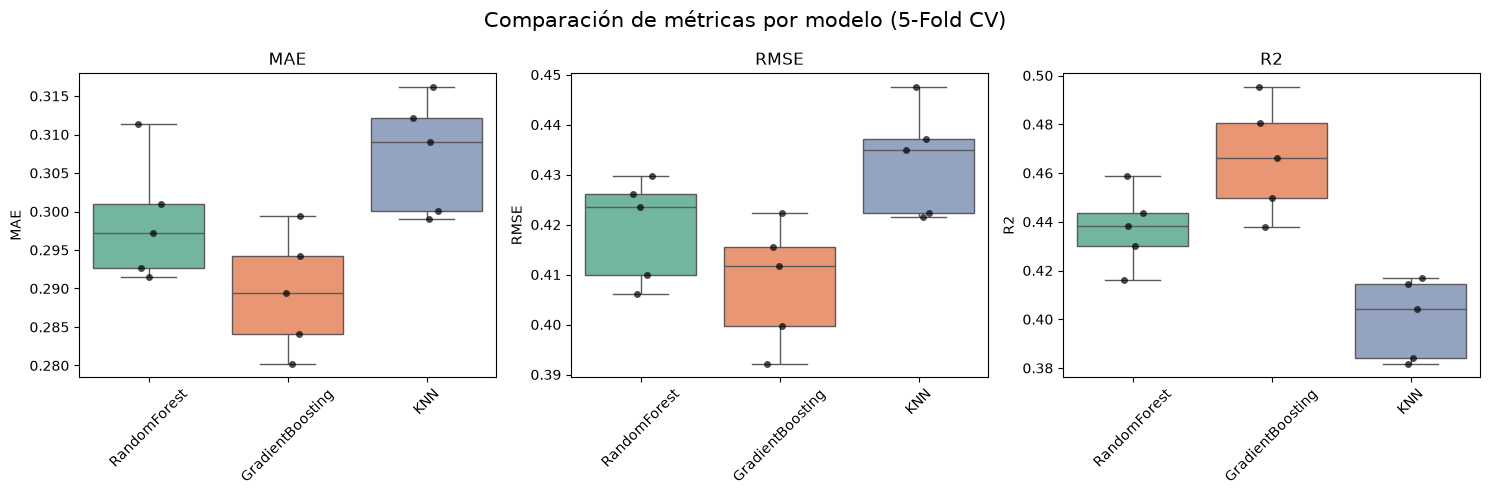

In [38]:
# Unificamos resultados en un solo dataframe
filas = []

for modelo, res in resultados.items():
    df = res["metricas"].copy().reset_index()   # recupera Fold como columna
    df["Modelo"] = modelo
    filas.append(df)

df_comparativo = pd.concat(filas, ignore_index=True)

metricas = ["MAE", "RMSE", "R2"]

modelos = df_comparativo["Modelo"].unique()

# Un color fijo por modelo
palette = dict(zip(modelos, sns.color_palette("Set2", n_colors=len(modelos))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, metrica in zip(axes, metricas):

    sns.boxplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        hue="Modelo",
        order=modelos,
        hue_order=modelos,
        palette=palette,
        dodge=False,
        showfliers=False,
        legend=False,
        ax=ax
    )

    sns.stripplot(
        data=df_comparativo,
        x="Modelo",
        y=metrica,
        order=modelos,
        color="black",
        alpha=0.7,
        jitter=True,
        size=5,
        ax=ax
    )

    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=45)

fig.suptitle("Comparación de métricas por modelo (5-Fold CV)", fontsize=15)
plt.tight_layout()
plt.show()

A partir de los boxplots obtenidos mediante validación cruzada de 5 folds, se observa que los tres modelos presentan una variabilidad relativamente acotada en sus métricas, lo que sugiere un comportamiento razonablemente consistente entre las distintas particiones de los datos.

Gradient Boosting se destaca por obtener sistemáticamente los mejores resultados en MAE, RMSE y R², aunque presenta cierta variabilidad entre folds. Por su parte, Random Forest muestra resultados relativamente estables, pero con un rendimiento predictivo inferior, mientras que KNN presenta las peores métricas de manera consistente.

En conjunto, los resultados favorecen a Gradient Boosting por su mejor desempeño predictivo, aunque no necesariamente por presentar la menor dispersión entre folds.

In [39]:
metricas_ajuste = []

for nombre, resultado in resultados.items():

    modelo = resultado["best_estimator"]

    # Predicciones
    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    # Métricas de validación cruzada
    metricas_cv = resultado["metricas"].mean()

    metricas_ajuste.append({
        "Modelo": nombre,
        "R² Train": r2_score(y_train, pred_train),
        "R² CV": metricas_cv["R2"],
        "R² Test": r2_score(y_test, pred_test),
        "RMSE Train": np.sqrt(mean_squared_error(y_train, pred_train)),
        "RMSE CV": metricas_cv["RMSE"],
        "RMSE Test": np.sqrt(mean_squared_error(y_test, pred_test))
    })

df_ajuste = pd.DataFrame(metricas_ajuste).set_index("Modelo")

# Diferencia entre entrenamiento y validación
df_ajuste["Diferencia R²"] = (
    df_ajuste["R² Train"] - df_ajuste["R² CV"]
)

display(df_ajuste.round(4))

,R² Train,R² CV,R² Test,RMSE Train,RMSE CV,RMSE Test,Diferencia R²
Modelo,,,,,,,
RandomForest,0.6264,0.4373,0.4559,0.3416,0.4191,0.4057,0.1891
GradientBoosting,0.6012,0.4659,0.4861,0.3530,0.4083,0.3943,0.1353
KNN,1.0000,0.4003,0.4105,0.0000,0.4327,0.4223,0.5997


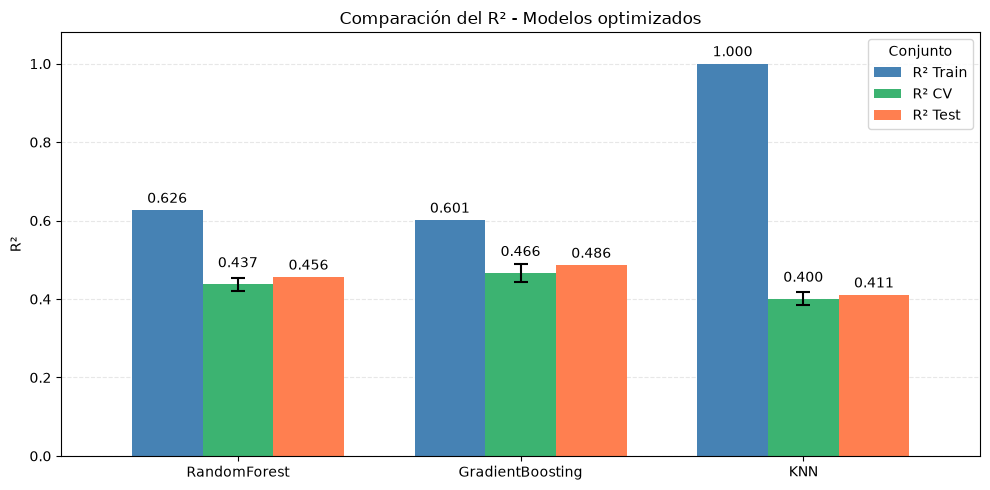

In [40]:
# Calculamos el desvío estándar del R² entre los 5 folds
std_cv = pd.Series({
    nombre: res["metricas"]["R2"].std()
    for nombre, res in resultados.items()
})

# Gráfico
ax = df_ajuste[
    ["R² Train", "R² CV", "R² Test"]
].plot(
    kind="bar",
    figsize=(10, 5),
    rot=0,
    width=0.75,
    color=["steelblue", "mediumseagreen", "coral"]
)

# Mostramos los valores sobre las barras
for i, container in enumerate(ax.containers):
    padding = 10 if i == 1 else 3  # CV es la segunda barra
    ax.bar_label(container, fmt="%.3f", padding=padding)

# Agregamos barras de error únicamente al R² CV
barras_cv = ax.containers[1]

x_cv = [
    barra.get_x() + barra.get_width() / 2
    for barra in barras_cv
]

ax.errorbar(
    x=x_cv,
    y=df_ajuste["R² CV"],
    yerr=std_cv.reindex(df_ajuste.index),
    fmt="none",
    ecolor="black",
    capsize=5,
    elinewidth=1.5,
    capthick=1.5
)

ax.set_title("Comparación del R² - Modelos optimizados")
ax.set_xlabel("")
ax.set_ylabel("R²")

# Ajustamos los límites para que entren las barras de error
r2_max = max(
    df_ajuste[["R² Train", "R² Test"]].max().max(),
    (df_ajuste["R² CV"] + std_cv.reindex(df_ajuste.index)).max()
)

ax.set_ylim(0, r2_max + 0.08)

ax.legend(title="Conjunto")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

Comparamos con los modelos en default

In [41]:
nombres = [
    "Random Forest",
    "Gradient Boosting",
    "KNN"
]

comparacion = []

for nombre, fila in df_ajuste.iterrows():

    r2_train_default = df_default.loc[
        (nombre, "Train"), "R2"
    ]

    r2_test_default = df_default.loc[
        (nombre, "Test"), "R2"
    ]

    comparacion.append({
        "Modelo": nombre,
        "Brecha Default": r2_train_default - r2_test_default,
        "Brecha Optimizado": fila["R² Train"] - fila["R² Test"],
        "R² Test Default": r2_test_default,
        "R² Test Optimizado": fila["R² Test"]
    })

df_comparacion_ajuste = pd.DataFrame(comparacion).set_index("Modelo")

display(df_comparacion_ajuste.round(4))

,Brecha Default,Brecha Optimizado,R² Test Default,R² Test Optimizado
Modelo,,,,
RandomForest,0.4686,0.1705,0.4511,0.4559
GradientBoosting,0.0365,0.1151,0.4652,0.4861
KNN,0.2415,0.5895,0.3087,0.4105


### Análisis del sobreajuste después de la optimización

A partir de la comparación del R² entre entrenamiento, validación cruzada y prueba, podemos ver cómo cambió el comportamiento de los tres modelos después de optimizar sus hiperparámetros.

**Random Forest** logró reducir considerablemente el sobreajuste, pasando de una brecha de 0.4666 a 0.1695 entre entrenamiento y test. Sin embargo, la mejora predictiva fue muy pequeña, con un R² en test que pasó de 0.4528 a 0.4559.

**Gradient Boosting** sigue mostrando el mejor equilibrio entre ajuste y capacidad predictiva. Aunque su brecha aumentó de 0.0405 a 0.1126, consiguió mejorar su R² en test de 0.4618 a 0.4867, obteniendo el mejor resultado de los tres modelos. Además, los valores de validación cruzada (0.466) y test (0.487) son bastante cercanos, lo que es una buena señal de generalización.

Por último, **KNN** presentó el mayor sobreajuste, alcanzando un R² perfecto de 1.000 en entrenamiento, pero de apenas 0.400 en validación cruzada y 0.411 en test. A pesar de esto, fue el modelo que más mejoró su capacidad predictiva respecto de la configuración inicial, pasando de 0.3086 a 0.4105 en test.

En cuanto a las **barras de error de la validación cruzada**, se observa que son relativamente pequeñas para los tres modelos. Esto indica que sus resultados no varían demasiado entre los cinco folds, incluso en el caso de KNN, que presenta un fuerte sobreajuste. También es interesante que los valores de test se encuentran bastante cerca de los promedios de validación cruzada.

En conclusión, Si bien **Gradient Boosting obtuvo el mejor desempeño predictivo**, las diferencias respecto de Random Forest fueron relativamente pequeñas, tanto en validación cruzada como en test, con mejoras del R² de aproximadamente 0.028 y 0.031, respectivamente.
Por lo tanto, aunque Gradient Boosting se seleccionó como el mejor modelo por sus métricas, ambos algoritmos mostraron un rendimiento predictivo bastante similar.